# Customers Like You: analysis

In [1]:
import os, sys, json
os.chdir('..') if os.path.basename(os.getcwd())=='notebooks' else None
sys.path.insert(0,'src')
import pandas as pd
from IPython.display import Image, Markdown, display

## DE1 to DE6: profile, clean, split, matrix

In [2]:
!python src/build_matrix.py
display(pd.read_csv('outputs/de1_data_profile.csv'))
display(pd.read_csv('outputs/de2_cleaning_log.csv'))

python: can't open file 'c:\\Users\\osafo\\Desktop\\main\\school\\neu_fall2\\ds5020\\miniproject1\\src\\build_matrix.py': [Errno 2] No such file or directory


,column,dtype,n_missing,pct_missing,n_unique
0,Invoice,object,0,0.00,53628
1,StockCode,object,0,0.00,5305
2,Description,object,4382,0.41,5698
3,Quantity,int64,0,0.00,1057
4,InvoiceDate,datetime64[us],0,0.00,47635
5,Price,float64,0,0.00,2807
6,Customer ID,float64,243007,22.77,5942
7,Country,str,0,0.00,43
8,sheet,str,0,0.00,2


,rule,rows_removed,rows_remaining,reason,pct_of_raw_removed
0,Raw data (start),0,1067371,NaN,0.00
1,1. Cancellation invoices (Invoice starts with ...,19494,1047877,A cancelled order is not a purchase.,1.83
2,2. Quantity <= 0,3457,1044420,Returns/adjustments are not purchases.,0.32
3,3. Price <= 0,2750,1041670,Zero/negative price lines are not real sales.,0.26
4,4. Non-product StockCode (not 5 digits + optio...,4793,1036877,"POST, M, D, DOT, BANK CHARGES, gift vouchers e...",0.45
5,5. Missing Customer ID,234245,802632,No customer row to put the purchase in (~1/5 o...,21.95
6,"(info) Exact duplicate lines, NOT removed",0,802632,"11,930 duplicates kept; they add quantity, not...",0.00


In [3]:
for f in ['de3_split_report','de5_matrix_report']:
    display(Markdown(open(f'outputs/{f}.md').read()))

### DE3 split and hold-out report

| Item | Value |
|---|---:|
| cutoff_date | 2011-10-09 |
| train_lines | 683,670 |
| products_before_filter | 4,529 |
| products_after_filter | 3,686 |
| min_customers | 10 |
| purchase_value | log |
| test_lines | 118,962 |
| test_unique_customer_product_pairs | 95,278 |
| dropped_customer_not_in_train | 13,840 |
| dropped_product_not_in_train_catalogue | 4,762 |
| dropped_already_bought_in_train | 31,754 |
| heldout_pairs | 44,922 |
| test_customers_evaluated | 1,913 |
| test_customers_total | 2,423 |


### DE5 matrix report

| Item | Value |
|---|---:|
| n_customers | 5,471 |
| n_products | 3,686 |
| non_zeros | 413,691 |
| sparsity_pct | 97.95 |
| avg_products_per_customer | 75.6 |
| dense_memory_MB | 161.3 |
| sparse_memory_MB | 4.99 |
| dense_over_sparse | 32.4 |
| k50_factors_MB | 3.66 |


## ML1 to ML7: model, evaluation, comparison, segments

python: can't open file 'c:\\Users\\osafo\\Desktop\\main\\school\\neu_fall2\\ds5020\\miniproject1\\src\\ml_analysis.py': [Errno 2] No such file or directory


# ML1 Decision note (write this BEFORE fitting anything)

**Main model: Truncated SVD.  Comparison model: PCA (ML5).**

Edit this note with your own reasoning. Starting points:

- The purchase matrix is large and sparse. Truncated SVD works on it directly;
  PCA centres the columns, which turns the zeros into small negative numbers and
  makes the matrix dense (or forces special solvers).
- A recommender needs customer factors AND product factors from one fit. SVD
  gives both (U S and V).
- Without centring, SVD describes what customers actually bought. PCA describes
  how they differ from the average customer, which is not the same question as
  "what do customers like you also buy".
- Hypothesis to test in ML5: both methods give similar hit rates, but SVD is
  faster / lighter, and PCA's first component is more interpretable.

Written on: (date)   Author: (name)


,k,rel_recon_error,energy_kept,val_hit_rate_at_10,val_baseline_hit_rate,fit_seconds
0,10,0.8761,0.2324,0.2686,0.3467,0.08
1,20,0.8459,0.2845,0.3947,0.3467,0.09
2,50,0.7895,0.3767,0.5085,0.3467,0.22
3,100,0.7274,0.4709,0.5387,0.3467,0.40
4,200,0.6388,0.5919,0.5898,0.3467,0.78


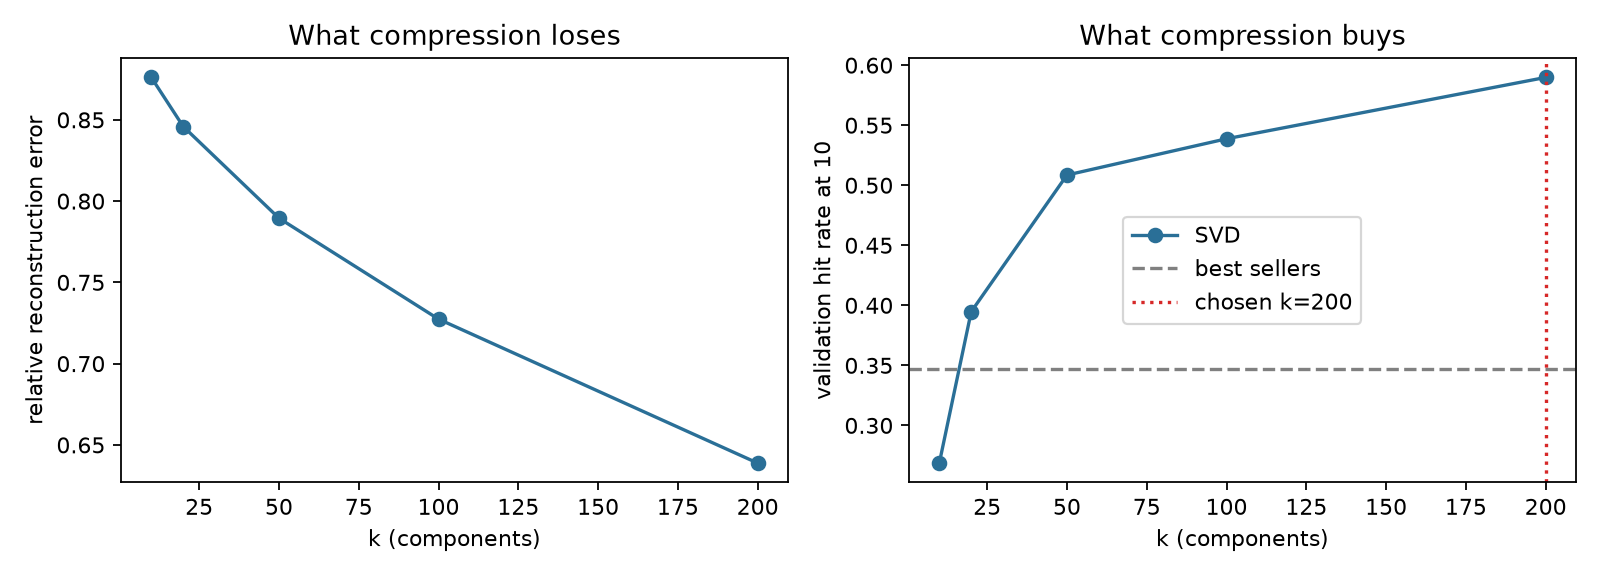

In [4]:
!python src/ml_analysis.py
display(Markdown(open('outputs/ml1_decision_note.md').read()))
display(pd.read_csv('outputs/ml2_k_sweep.csv'))
display(Image('outputs/fig_ml2_k_sweep.png'))

In [5]:
display(Markdown(open('outputs/ml5_comparison_table.md').read()))
display(pd.read_csv('outputs/ml4_results.csv'))
display(pd.read_csv('outputs/ml7_sensitivity.csv'))

| Measure | PCA | Truncated SVD |
|---|---|---|
| k used | 200 | 200 |
| Fit time (seconds) | 0.74 | 0.81 |
| Peak memory during fit (MB) | 25.2 | 26.6 |
| Size of stored factors (MB) | 14.68 | 14.65 |
| Variance explained / relative reconstruction error | 57.5% variance explained; rel. error 0.638 | rel. error 0.639 (59.2% of energy kept) |
| Hit rate at 10 on held-out purchases | 21.9% | 22.0% |
| Best-seller baseline hit rate at 10 | 27.0% | 27.0% |
| What component 1 represents (auto-draft: rewrite in your words) | Main way customers differ from the average customer. Pushes up: PACK OF 72 RETROSPOT CAKE CASE; JUMBO BAG RED RETROSPOT; LUNCH BAG RED RETROSPOT; WHITE HANGING HEART T-LIGHT HO. Pushes down: AMBER GLASS TASSLE BAG CHARM; PURPLE GLASS TASSLE BAG CHARM; BROWN ANTIQUE CUBE CANDLE; WHITE HYDRANGEA ART FLOWER. | Overall purchase volume: 100% of products load with the same sign; score tracks number of products bought (r=0.89) and total value (r=0.97). |


,model,hit_rate_at_10
0,Truncated SVD,0.2196
1,PCA,0.2190
2,Best sellers,0.2703


,purchase_value,hit_rate_at_10,baseline_hit_rate
0,log,0.2196,0.2703
1,binary,0.2473,0.2703
2,count,0.1349,0.2703


,segment,name,draft_name,customers,share_pct,median_products_bought,median_total_value,top_countries,top_products
0,0,Light UK buyers: Feng Shui Pillar Candle fans,Light UK buyers: Feng Shui Pillar Candle fans,1929,35.3,20.0,39.23,"United Kingdom 94%, Germany 1%, France 1%",FENG SHUI PILLAR CANDLE | ASS COL SMALL SAND F...
1,1,Core UK buyers: White Hanging Heart T-Light fans,Core UK buyers: White Hanging Heart T-Light fans,1179,21.5,51.0,99.23,"United Kingdom 97%, Cyprus 0%, Spain 0%",WHITE HANGING HEART T-LIGHT HO | ASSORTED COLO...
2,2,Heavy mostly-UK buyers: Jumbo Bag Red Retrospo...,Heavy mostly-UK buyers: Jumbo Bag Red Retrospo...,676,12.4,78.0,177.17,"United Kingdom 88%, Germany 3%, France 3%",JUMBO BAG RED RETROSPOT | LUNCH BAG RED RETROS...
3,3,Heavy mostly-UK buyers: World War 2 Gliders As...,Heavy mostly-UK buyers: World War 2 Gliders As...,1005,18.4,61.0,131.82,"United Kingdom 87%, Germany 3%, France 3%",WORLD WAR 2 GLIDERS ASSTD DESI | VINTAGE SNAP ...
4,4,Heavy mostly-UK buyers: Pack Of 72 Retrospot C...,Heavy mostly-UK buyers: Pack Of 72 Retrospot C...,682,12.5,61.5,136.95,"United Kingdom 83%, Germany 3%, France 3%",PACK OF 72 RETROSPOT CAKE CASE | 60 TEATIME FA...


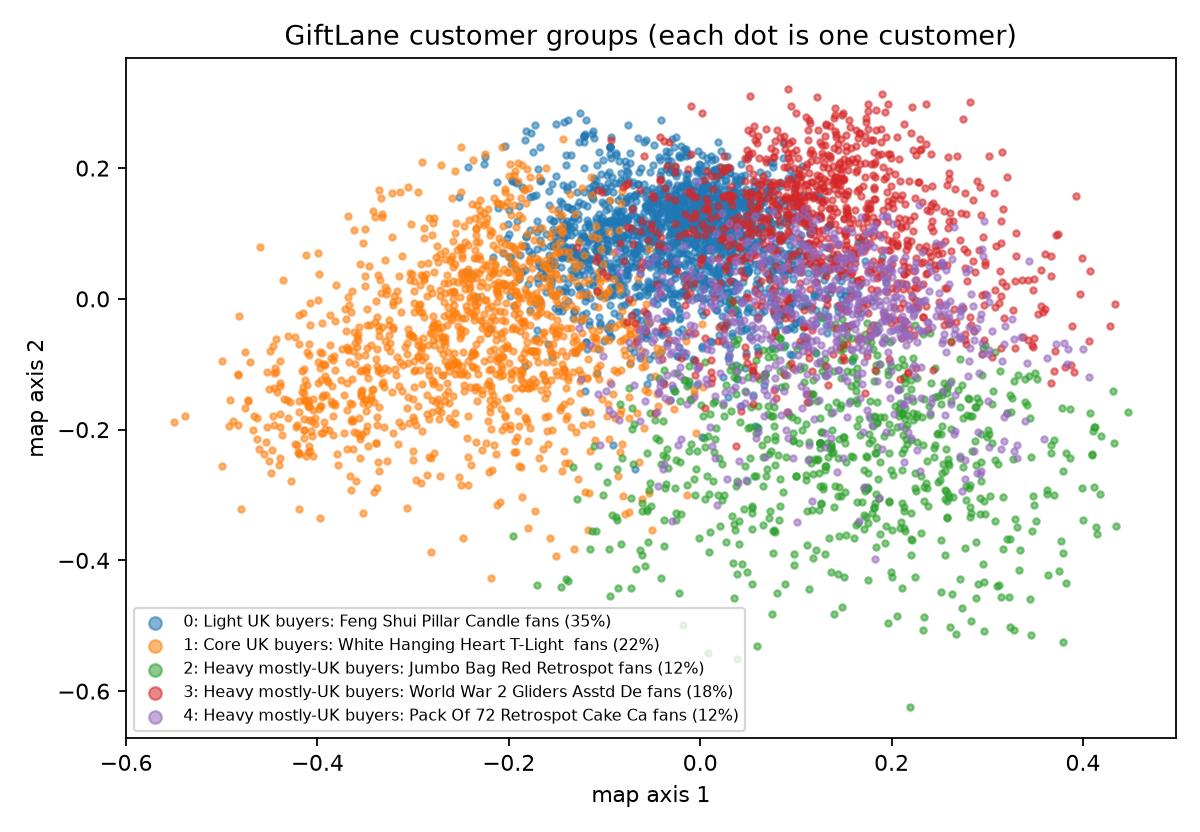

,product,rank,also_bought
0,WHITE HANGING HEART T-LIGHT HOLDER,1,RED HANGING HEART T-LIGHT HOLDER
1,WHITE HANGING HEART T-LIGHT HOLDER,2,CANDLEHOLDER PINK HANGING HEART
2,WHITE HANGING HEART T-LIGHT HOLDER,3,RED HANGING METAL STAR TLIGHT HLDR
3,WHITE HANGING HEART T-LIGHT HOLDER,4,"WHITE PEARL BEADED HEART, SMALL"
4,WHITE HANGING HEART T-LIGHT HOLDER,5,WHITE HYDRANGEA ART FLOWER
5,WHITE HANGING HEART T-LIGHT HOLDER,6,JAZZ HEARTS SPIRAL NOTEPAD
6,WHITE HANGING HEART T-LIGHT HOLDER,7,LADS ONLY TISSUE BOX
7,WHITE HANGING HEART T-LIGHT HOLDER,8,AMBER GLASS/SILVER BRACELET
8,WHITE HANGING HEART T-LIGHT HOLDER,9,BLUE ROUND COMPACT MIRROR
9,WHITE HANGING HEART T-LIGHT HOLDER,10,HANGING METAL BIRD BATH


In [6]:
display(pd.read_csv('outputs/ml6_segments.csv'))
display(Image('outputs/fig_ml6_customer_map.png'))
display(pd.read_csv('outputs/ml3_similar_products_examples.csv').head(20))

## Your interpretation (write in your own words)
- Does SVD beat best sellers? By how much, with what interval?
- PCA vs SVD: what differs in speed, memory, hit rate, component 1?
- Does the purchase value (ML7) change the conclusion?
- Are the segment names sensible? What would you rename?